# F03.04 · La primera red neuronal: ¿aprende una red lo que vio XGBoost en el último minuto?

> 🧭 **En 30 segundos**
> - **Para qué:** construir y entrenar la **primera red neuronal** de predicción (⏳ preictal frente a 💤 interictal) con lo que decidió F03.03: **60 s de contexto** y **cada paciente comparado consigo mismo**.
> - **Entra:** las ventanas de **F03.01**, la señal de **F02.02** (para leer el contexto), la decisión de **F03.03** y sus puntuaciones (para comparar) → **Sale:** tres redes entrenadas (con 60 s, con 4 s y con el mismo peso por paciente), su nota en 🟡 dev **ventana a ventana frente a XGBoost**, por paciente, por grupo de crisis y en el control de sesión, y los modelos guardados.
> - **Idea clave:** la red es **CNN + GRU**. La CNN resume cada ventana de 4 s; la GRU lee las 15 ventanas del último minuto **en orden**. A diferencia de XGBoost, que solo veía un resumen (media, variación, cambio), la red puede ver **cómo evoluciona** el minuto.

> 📍 **Dónde estamos: Fase 3 · notebook 4 (F03.04).** F03.02 dejó la línea base (≈ azar con la ventana sola). F03.03 vio que mirar 60 s atrás **y** comparar a cada paciente consigo mismo sí separa ⏳ de 💤 con XGBoost. Esa es la nota que tiene que superar la red.

> 🔄 **Es dinámico.** Lee lo que dejaron F03.01, F03.02 y F03.03; las cifras, las comparaciones y las conclusiones salen de los datos al ejecutarlo.

> 🔒 **Regla de oro de la Fase 3: aquí no se mira 🟢 eval.** Todo se decide con 🟡 dev.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Siguiendo con el ejemplo del médico y la tensión arterial de F03.03:

1. **XGBoost (F03.03)** recibía un **resumen** del último minuto: "la media de la tensión fue 13, se movió poco y la de ahora es algo más alta". Con eso ya separa algo ⏳ de 💤.
2. **La red** recibe las **15 medidas en orden**, cada una completa (el espectro entero, no 5 bandas), y aprende **ella sola** qué mirar: puede notar "empezó a subir hace 30 s y no ha parado", que un resumen no ve.
3. Lo que **no cambia**: cada paciente se compara consigo mismo (su "normal" sale de sus momentos tranquilos), igual que en F03.03.

Este notebook responde a cuatro preguntas:

| Pregunta | Dónde se responde |
|---|---|
| ¿La red supera a XGBoost de F03.03 con las mismas ventanas? | §8 y §9 (recuadro dorado) |
| ¿Le sirve a la red mirar 60 s, o le basta la ventana actual? | §9 (red de 60 s frente a red de 4 s) |
| ¿Acierta en la mayoría de pacientes o solo en unos pocos? ¿Y en cada grupo de crisis? | §10 |
| ¿Predice la crisis o reconoce la grabación? | §11 (control de sesión) |

## El recorrido de este notebook

![El recorrido del notebook F03.04](img/mapa_notebook_04.png)

👀 **Qué enseña.** Los seis pasos, en orden. Los dos en rojo son los importantes: **entrenar** las redes (§7) y **compararlas** con XGBoost de F03.03 con las mismas ventanas (§8-§11). Abajo, contra qué se compara siempre.

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Red neuronal** | Una función con muchos números ajustables (**pesos**) que se van corrigiendo con los ejemplos hasta que acierta. Esta tiene unos 50.000 |
| **CNN** (red convolucional) | Capas que pasan un **filtro** pequeño a lo largo de un eje (aquí, la frecuencia) buscando formas: "un pico en 8-12 Hz", "mucha energía lenta". Ver §6 |
| **GRU** (*Gated Recurrent Unit*) | Una capa que lee una **secuencia en orden** con una **memoria**; en cada paso decide con dos "puertas" qué conserva y qué reescribe. Ver §6 |
| **Espectro relativo** | Qué parte de la energía de un canal cae en cada frecuencia (de 1 a 40 Hz). Lo que ve la red de cada ventana. Ver §4 |
| **Época** | Una pasada completa por todos los datos de entrenamiento |
| **Pérdida** (*loss*) | El número que mide cuánto se equivoca la red al entrenar; lo que el entrenamiento intenta bajar |
| **Parada temprana** | Quedarse con la red de la época que mejor nota saca en 🟡 dev y parar cuando deja de mejorar. Ver §7 |
| **Sobreajuste** | Aprenderse los ejemplos (aquí, los pacientes de train) en vez de la regla general: mejora en train y empeora en dev |
| **Semilla** | El número que fija el azar (pesos iniciales, orden de los lotes). Con otra semilla la misma red sale algo distinta; por eso se entrenan **tres** y se promedian |
| **Diferencia emparejada** | Comparar dos modelos con las mismas ventanas y los mismos sorteos de pacientes: su intervalo dice si una mejora es real (F03.03 §9) |
| **AUC-ROC** | La nota: 0,5 = azar, 1 = perfecto (F03.02 §5) |

## 0. Los parámetros

- `CONJUNTO`: `general` es el modelo principal. Para las ausencias, `grupo_ausencia` (antes hay que ejecutar F03.01, F03.02 y F03.03 con ese conjunto).
- `MODO_PRUEBA`: `True` para comprobar que todo funciona en pocos minutos (un 10 % de las ventanas, 1 semilla, 2 épocas). Las cifras no valen; los ficheros se guardan con `_prueba`.

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill cambiando solo estos valores.)*

> **`CONJUNTO` se fija en un solo sitio para toda la Fase 3:** `tfm_comun/prediccion/estudio.py` (`CONJUNTO_ESTUDIO`). Aquí se deja en `None`; solo se pone otro valor para una prueba puntual (o desde papermill). Los resultados de cada conjunto van a su carpeta: `outputs/fase_03/<conjunto>/`.

In [1]:
CONJUNTO = None   # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3); se puede poner otro aquí
MODO_PRUEBA = False

## 1. Librerías

> 🎯 **Qué hacemos:** comprobar que están instaladas las librerías (las de la línea base + **PyTorch**, con CUDA si hay tarjeta NVIDIA).

In [2]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_RED
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_RED)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características
torch,✅,2.15.0+cu132,"la red neuronal: capas, entrenamiento en la GPU (PyTorch)"


Todo lo necesario está instalado.


In [3]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
from functools import partial
import re
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import torch
from scipy.stats import rankdata
from sklearn.metrics import roc_curve
from tqdm.auto import tqdm
from IPython.display import display, Markdown

from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_03, RUTA_SENALES, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.dispositivo import elegir_dispositivo
from tfm_comun.entorno.configuracion import leer_configuracion
from tfm_comun.entorno.nombres_fichero import nombre_fichero
from tfm_comun.senal.bandas import BANDAS_HZ
from tfm_comun.senal.montaje import CANALES_TCP
from tfm_comun.red.paquetes import cargar_paquete
from tfm_comun.red.reproducibilidad import fijar_semillas
from tfm_comun.red.entradas.espectro_relativo import espectro_relativo
from tfm_comun.red.entradas.rango_frecuencias import frecuencias_entrada
from tfm_comun.red.lotes.secuencias_espectro import SecuenciasEspectro
from tfm_comun.red.lotes.orden_epoca import peso_por_paciente
from tfm_comun.red.redes.cnn_gru import ARQUITECTURA
from tfm_comun.red.modelo import crear_red, contar_parametros
from tfm_comun.red.entreno.entrenar_red import ENTRENAMIENTO, entrenar_red
from tfm_comun.red.entreno.puntuacion import puntuar_red
from tfm_comun.prediccion.almacen_caracteristicas import caracteristicas_al_dia, guardar_caracteristicas, cargar_caracteristicas
from tfm_comun.prediccion.contextos.duracion import ventanas_por_contexto
from tfm_comun.prediccion.contextos.disponibilidad import con_contexto_completo, inicios_necesarios, clave
from tfm_comun.prediccion.contextos.calculo import caracteristicas_de_inicios
from tfm_comun.prediccion.contextos.indices import indices_contexto
from tfm_comun.prediccion.normalizacion_paciente import calibracion_por_paciente
from tfm_comun.prediccion.validacion import rondas_validacion
from tfm_comun.prediccion.evaluacion.auroc_global import auroc_con_intervalo, diferencia_auroc_con_intervalo
from tfm_comun.prediccion.evaluacion.auroc_paciente import auroc_por_paciente
from tfm_comun.prediccion.evaluacion.sensibilidad import sensibilidad_con_especificidad
from tfm_comun.prediccion.control_sesion import controles_de_sesion
from tfm_comun.prediccion.evaluacion.lectura import lectura_diferencia
from tfm_comun.visual.iconos import con_icono
from tfm_comun.visual.colores import COLORES_PERIODO, COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo, con_signo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, torch)

# El conjunto: si la celda de parámetros lo deja en None, el de tfm_comun/prediccion/estudio.py
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)


Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
sklearn     1.9.1
torch       2.15.0+cu132


## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" del notebook, leer lo que dejaron F03.01, F03.02 y F03.03 y elegir dónde se entrena (GPU o procesador).
>
> 🤔 **Por qué:** el **contexto** y la **normalización** no se eligen aquí: los decidió F03.03 (`decision_red` de su `configuracion.json`). Así la red se compara con XGBoost en igualdad de condiciones: misma información, mismas ventanas; solo cambia el modelo.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `VARIANTES` | 3 redes | **principal**: el contexto de F03.03 (60 s) · **sin contexto**: la misma red con solo la ventana actual (4 s), para medir si la red aprovecha el minuto · **mismo peso por paciente**: la principal, pero en cada época cada paciente sale las mismas veces (`WeightedRandomSampler`), como la variante de la línea base |
| `N_SEMILLAS` | 3 | Cada red se entrena 3 veces con distinta semilla y se **promedian** sus puntuaciones: la nota no depende de la suerte de una semilla, y se ve cuánto varía |
| `ARQUITECTURA` | `tfm_comun/red/redes/cnn_gru.py` | 32 filtros, resumen de 64 números por ventana, memoria de la GRU de 64, dropout 0,3 (§6) |
| `ENTRENAMIENTO` | `tfm_comun/red/entreno/entrenar_red.py` | Hasta 40 épocas, paciencia 6, lotes de 128, tasa de aprendizaje 0,001, weight decay 0,01, reflejo de hemisferios en el 50 % (§7) |
| `ESPECIFICIDAD` | 0,9 | Como en F03.02 y F03.03 |
| `N_BOOTSTRAP` | 500 | Sorteos de pacientes para los intervalos |
| `MEJORA_MINIMA` | 0,02 | Como en F03.03: por debajo, una mejora no compensa la complejidad de la red aunque sea "real" |

In [4]:
N_SEMILLAS = 3
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500
MEJORA_MINIMA = 0.02

In [5]:
SUFIJO = '_prueba' if MODO_PRUEBA else ''
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/04_red_prediccion' + SUFIJO)
RUTA_MODELOS = RUTA_RESULTADOS / 'modelos'
RUTA_MODELOS.mkdir(exist_ok=True)

# leer_config: el configuracion.json de un notebook anterior, comprobando que es de este CONJUNTO
# (tfm_comun/entorno/configuracion.py; para con un mensaje claro si falta o es de otro conjunto)
leer_config = partial(leer_configuracion, conjunto=CONJUNTO)
config_01 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json', 'F03.01 (fase_03/01_datos_red.ipynb)')
config_02 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '02_linea_base' / 'configuracion.json', 'F03.02 (fase_03/02_linea_base.ipynb)')
config_03 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'configuracion.json', 'F03.03 (fase_03/03_contexto_y_paciente.ipynb)')

SEMILLA = int(config_01['semilla'])
VENTANA_S = config_01['ventana_s']
MUESTRAS = int(config_01['muestras_por_ventana'])
FS = MUESTRAS / VENTANA_S
SPLITS = [s for s in ['train', 'dev'] if s in config_01['paquetes']]          # 🟢 eval NO se usa aquí
DECISION = config_03['decision_red']
CONTEXTO_S = int(DECISION['contexto_s'])
NORMALIZACION = DECISION['normalizacion']
K_RED = ventanas_por_contexto(CONTEXTO_S, VENTANA_S)                           # ventanas de 4 s que ve la red (15 con 60 s)
K_MAX = ventanas_por_contexto(max(config_03['contextos_s']), VENTANA_S)       # las MISMAS ventanas que F03.03
AUC_XGB = config_03['mejor']['auc_dev']
NOMBRE_XGB = f'XGBoost F03.03 ({config_03["mejor"]["contexto_s"]} s, {config_03["mejor"]["normalizacion"]})'

PRINCIPAL = f'red_{CONTEXTO_S}s'
VARIANTES = {PRINCIPAL: {'k': K_RED, 'mismo_peso': False,
                         'qué es': f'la red principal: {CONTEXTO_S} s de contexto ({K_RED} ventanas), la decisión de F03.03'}}
if K_RED > 1:
    VARIANTES[f'red_{VENTANA_S}s'] = {'k': 1, 'mismo_peso': False,
                                      'qué es': f'la misma red con solo la ventana actual ({VENTANA_S} s): ¿la red aprovecha el contexto?'}
VARIANTES[f'{PRINCIPAL}_mismo_peso'] = {'k': K_RED, 'mismo_peso': True,
                                        'qué es': 'la principal, pero cada paciente sale las mismas veces en cada época'}
SIN_CONTEXTO = f'red_{VENTANA_S}s' if K_RED > 1 else None
MISMO_PESO = f'{PRINCIPAL}_mismo_peso'

AJUSTES = dict(ENTRENAMIENTO)
if MODO_PRUEBA:
    N_SEMILLAS, AJUSTES['epocas_max'] = 1, 2

dispositivo, ficha = elegir_dispositivo()

tabla_variantes = pd.DataFrame({n: {'ventanas que ve': v['k'], 'segundos': v['k'] * VENTANA_S,
                                    'mismo peso por paciente': 'sí' if v['mismo_peso'] else 'no', 'qué es': v['qué es']}
                                for n, v in VARIANTES.items()}).T
tabla_variantes.index.name = 'variante'
display(con_separadores(tabla_variantes, decimales=0))
print(f'Conjunto: {CONJUNTO}{" · 🔴 MODO PRUEBA (cifras sin valor)" if MODO_PRUEBA else ""} · decisión de F03.03: {DECISION["texto"]} '
      f'({CONTEXTO_S} s, {NORMALIZACION})')
print(f'Dispositivo: {ficha["dispositivo"]} · {ficha["nombre"]}' + (f' · {ficha["memoria (GB)"]} GB' if ficha['memoria (GB)'] else '')
      + (f'\n{ficha["aviso"]}' if ficha['aviso'] else ''))
print(f'A superar en 🟡 dev: {NOMBRE_XGB} → AUC {decimal(AUC_XGB)}  ·  🟢 eval no se abre en este notebook')

,ventanas que ve,segundos,mismo peso por paciente,qué es
variante,,,,
red_4s,1,4,no,"la red principal: 4 s de contexto (1 ventanas), la decisión de F03.03"
red_4s_mismo_peso,1,4,sí,"la principal, pero cada paciente sale las mismas veces en cada época"


Conjunto: umbral_2min · decisión de F03.03: Ninguna palanca mejora de forma clara (4 s, ninguna)
Dispositivo: cuda (GPU NVIDIA) · NVIDIA GeForce RTX 3060 · 12.9 GB
A superar en 🟡 dev: XGBoost F03.03 (16 s, por_paciente_calibrado) → AUC 0,59  ·  🟢 eval no se abre en este notebook


### 🔙 De dónde venimos

![La historia de la Fase 3](img/historia_fase_03.png)

👀 **Qué enseña.** Las preguntas de la fase y lo que salió en cada notebook. Las cifras de abajo se leen de sus resultados:

In [6]:
control_03 = config_03.get('control_sesion')
control_03 = (control_03.get('veredicto', str(control_03)) if isinstance(control_03, dict) else
              str(control_03) if control_03 else '— (no está en su configuracion.json: vuelve a ejecutar F03.03 entero)')
historia = pd.DataFrame([
    ('F03.02 · XGBoost, ventana de 4 s sola', decimal(config_02['referencia']['auc_dev']),
     'casi el azar: a la ventana suelta le falta información' if config_02['referencia']['ic95_dev'][0] <= 0.5 else 'algo por encima del azar'),
    ('F03.02 · detectar la crisis con los mismos números', decimal(config_02.get('comprobacion_deteccion', {}).get('auc_dev', float('nan'))),
     'la cadena de datos funciona'),
    (f'F03.03 · {NOMBRE_XGB}', con_intervalo(AUC_XGB, *config_03['mejor']['ic95_dev']),
     f'{con_signo(config_03["mejor"]["diferencia_con_4s"])} sobre la ventana sola: ' + ('mejora real' if config_03['mejor']['ic95_diferencia'][0] > 0 else 'puede ser casualidad')),
    ('F03.03 · control de sesión', control_03, ''),
], columns=['qué se probó', 'AUC en 🟡 dev', 'lectura']).set_index('qué se probó')
mostrar_destacado('Lo que hereda la red', f'<b>{DECISION["texto"]}.</b> La red tiene que superar a XGBoost de F03.03 '
                  'con <b>las mismas ventanas</b>; si no lo supera, una red no compensa (todavía).', historia)

,AUC en 🟡 dev,lectura
qué se probó,,
"F03.02 · XGBoost, ventana de 4 s sola","0,56",algo por encima del azar
F03.02 · detectar la crisis con los mismos números,"0,79",la cadena de datos funciona
"F03.03 · XGBoost F03.03 (16 s, por_paciente_calibrado)","0,59 [0,54 – 0,65]","+0,042 sobre la ventana sola: puede ser casualidad"
F03.03 · control de sesión,🔴 Se cae: reconocía la grabación,


## 3. Qué ventanas: las mismas que F03.03

> 🎯 **Qué hacemos:** quedarnos con las ventanas de F03.01 que tienen detrás, dentro de su tramo, el **contexto más largo** que probó F03.03.
>
> 🤔 **Por qué:** así son **exactamente las mismas** ventanas con las que se midió XGBoost, y la comparación de §8-§9 es ventana a ventana. La red de 4 s (sin contexto) también se mide con ellas.

In [7]:
partes = []
for split in SPLITS:
    _, indice = cargar_paquete(CONJUNTO, split)
    partes.append(indice)
todas = pd.concat(partes, ignore_index=True)
completo = con_contexto_completo(todas, K_MAX, MUESTRAS)
if MODO_PRUEBA:                                    # un 10 % de las filas, al azar (solo para comprobar que todo funciona)
    completo &= np.random.default_rng(SEMILLA).random(len(todas)) < 0.1

filas_tabla = {}
for (split, clase), t in todas.groupby(['split', 'clase'], sort=False):
    c = completo[t.index]
    filas_tabla[(con_icono(split), con_icono(clase))] = {'ventanas en F03.01': len(t), 'las que se usan': int(c.sum()),
                                                         '% que se quedan': 100 * c.mean(), 'pacientes': t.patient[c].nunique()}
tabla_completo = pd.DataFrame(filas_tabla).T
tabla_completo.index.names = ['split', 'clase']
display(con_separadores(tabla_completo, decimales=1))

filas = todas[completo].reset_index(drop=True)
y = filas.etiqueta.to_numpy()
pacientes = filas.patient.to_numpy()
rondas = rondas_validacion(filas)
validar = np.any([v for _, _, v in rondas], axis=0)
for nombre, entrena, valida in rondas:
    assert not set(pacientes[entrena]) & set(pacientes[valida]), f'🔴 {nombre}: pacientes en entrenamiento y validación a la vez.'
iguales = len(filas) == config_03.get('ventanas_estudiadas')
print(f'Se usan {numero_legible(len(filas))} ventanas · entrenamiento: {numero_legible(int(filas.en_entrenamiento.sum()))} · '
      f'validación: {numero_legible(int(validar.sum()))} ({", ".join(n for n, _, _ in rondas)})')
print(('✅ Las mismas que estudió F03.03.' if iguales else
       f'🔴 F03.03 estudió {numero_legible(config_03.get("ventanas_estudiadas", 0))} ventanas y aquí hay {numero_legible(len(filas))}: '
       'la comparación con XGBoost (§8) solo usará las comunes. ¿Se volvió a ejecutar F03.01 después de F03.03?')
      if not MODO_PRUEBA else '🔴 Modo prueba: solo un 10 % de las ventanas.')

Se usan 70.812 ventanas · entrenamiento: 18.348 · validación: 52.464 (🟡 dev)
✅ Las mismas que estudió F03.03.


👀 **Cómo leer la tabla.** Para cada partición y clase: cuántas ventanas había en F03.01, cuántas tienen el contexto completo (las que se usan) y de cuántos pacientes. Debajo, si coinciden con las de F03.03.

✅ **Qué deberías ver:** las mismas cifras que en la tabla de §3 de F03.03 y el ✅ de abajo.

## 4. Qué ve la red de cada ventana: su espectro relativo

> 🎯 **Qué hacemos:** calcular, para **cada ventana de 4 s que forma parte de algún contexto**, su espectro relativo: 22 canales × 40 frecuencias (1-40 Hz) = 880 números.
>
> 🤔 **Por qué:** es lo mismo que usaba XGBoost (potencia relativa), pero **sin agruparlo en 5 bandas**: la red decide sola qué frecuencias importan. La normalización por paciente de F03.03 necesita números comparables entre ventanas, y el espectro lo es (la onda en bruto nunca se repite igual).

![Qué ve la red de cada ventana](img/de_ventana_a_espectro.png)

👀 **Qué enseña.** De izquierda a derecha: la ventana de 4 s (22 canales de señal), el espectro de uno de sus canales (cuánta energía hay en cada frecuencia; en rojo, el pico alfa típico) y la matriz de 22 × 40 que entra en la red. Abajo, las tres razones de esta elección.

> 💡 La primera vez es lo más lento del notebook: se leen de la señal unas centenas de miles de ventanas (como en F03.03, de 15 a 40 minutos). Se guarda y las siguientes veces tarda segundos.

In [8]:
inicio = time.time()
FRECUENCIAS = frecuencias_entrada(FS)
N_CANALES, N_FRECUENCIAS = len(CANALES_TCP), len(FRECUENCIAS)
necesarias = inicios_necesarios(filas, K_RED, MUESTRAS)
claves = clave(necesarias.ruta, necesarias.inicio)
nombre_almacen = f'espectro_{CONJUNTO}{SUFIJO}'
if caracteristicas_al_dia(nombre_almacen, 'train_dev', claves, N_CANALES * N_FRECUENCIAS):
    estado = 'ya estaba al día'
else:
    estado = 'calculado'
    valores = caracteristicas_de_inicios(necesarias, RUTA_SENALES, FS, MUESTRAS, calcular=espectro_relativo,
                                         progreso=lambda it, total: tqdm(it, total=total, desc='tramos de F02.02 leídos'))
    guardar_caracteristicas(nombre_almacen, 'train_dev', claves, valores)
valores, claves_guardadas = cargar_caracteristicas(nombre_almacen, 'train_dev')
indices = indices_contexto(filas, K_RED, MUESTRAS, claves_guardadas)      # (filas, 15): qué ventanas forman cada secuencia
tabla_lectura = pd.DataFrame({'estado': [estado], 'ventanas de 4 s calculadas': [len(claves_guardadas)],
                              'números por ventana': [valores.shape[1]], 'secuencias (filas)': [len(filas)],
                              'ventanas por secuencia': [indices.shape[1]], 'GB en memoria': [valores.nbytes / 1e9],
                              'minutos': [(time.time() - inicio) / 60]}, index=[CONJUNTO])
tabla_lectura.index.name = 'conjunto'
display(con_separadores(tabla_lectura, decimales=1))

tramos de F02.02 leídos:   0%|          | 0/3163 [00:00<?, ?it/s]

,estado,ventanas de 4 s calculadas,números por ventana,secuencias (filas),ventanas por secuencia,GB en memoria,minutos
conjunto,,,,,,,
umbral_2min,calculado,70.812,880,70.812,1,"0,2","1,9"


👀 **Cómo leer la tabla.** Cuántas ventanas de 4 s distintas se han calculado (cada una **una sola vez**, aunque forme parte del contexto de muchas filas), cuántos números tiene cada una (880 = 22 × 40), cuántas secuencias de 15 ventanas se montan con ellas y cuánta memoria ocupan.

✅ **Qué deberías ver:** unas cifras parecidas a las de §4 de F03.03 (mismas ventanas). La segunda vez, *ya estaba al día*.

Antes de entrenar, una figura dice si en el espectro **de la ventana actual** hay alguna diferencia media entre ⏳ y 💤:

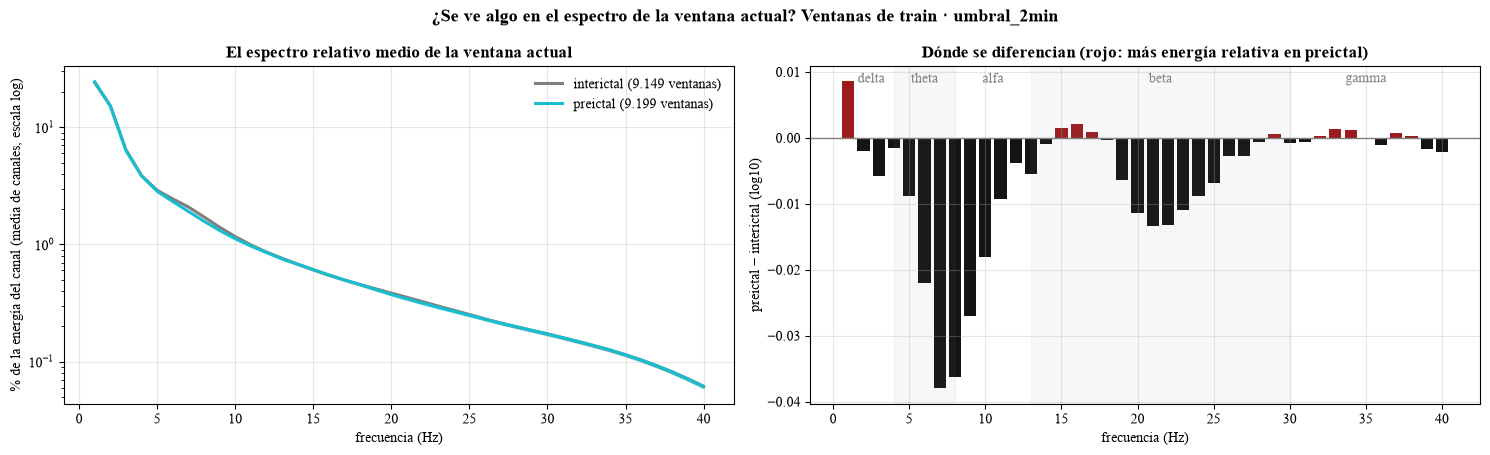

In [9]:
en_entrena = filas.en_entrenamiento.to_numpy(dtype=bool)
actual = valores[indices[en_entrena, -1]].reshape(-1, N_CANALES, N_FRECUENCIAS)      # la ventana actual de cada fila de train
y_entrena = y[en_entrena]
with plt.rc_context(ESTILO_TIMES):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6))
    medias = {}
    for clase, etiqueta in [('interictal', 0), ('preictal', 1)]:
        por_fila = np.nanmean(actual[y_entrena == etiqueta], axis=1)                        # media de los canales
        medias[clase] = np.nanmean(por_fila, axis=0)
        error = 1.96 * np.nanstd(por_fila, axis=0) / np.sqrt(np.sum(~np.isnan(por_fila), axis=0))
        ax1.plot(FRECUENCIAS, 100 * 10 ** medias[clase], color=COLORES_PERIODO[clase], lw=2.2, label=f'{clase} ({numero_legible(int((y_entrena == etiqueta).sum()))} ventanas)')
        ax1.fill_between(FRECUENCIAS, 100 * 10 ** (medias[clase] - error), 100 * 10 ** (medias[clase] + error), color=COLORES_PERIODO[clase], alpha=0.25)
    ax1.set_yscale('log')
    ax1.set_xlabel('frecuencia (Hz)')
    ax1.set_ylabel('% de la energía del canal (media de canales, escala log)')
    ax1.set_title('El espectro relativo medio de la ventana actual', fontsize=12, fontweight='bold')
    ax1.legend(frameon=False)
    diferencia = medias['preictal'] - medias['interictal']
    ax2.bar(FRECUENCIAS, diferencia, color=np.where(diferencia > 0, COLORES_ESQUEMA['rojo'], COLORES_ESQUEMA['negro']), width=0.8)
    ax2.axhline(0, color='gray', lw=1)
    for banda, (baja, alta) in BANDAS_HZ.items():
        ax2.axvspan(max(baja, FRECUENCIAS[0] - 0.5), min(alta, FRECUENCIAS[-1] + 0.5), color='gray', alpha=0.06 if list(BANDAS_HZ).index(banda) % 2 else 0)
        ax2.text((max(baja, 1) + min(alta, 40)) / 2, 0.98, banda, transform=ax2.get_xaxis_transform(), ha='center', va='top', fontsize=10, color='gray')
    ax2.set_xlabel('frecuencia (Hz)')
    ax2.set_ylabel('preictal − interictal (log10)')
    ax2.set_title('Dónde se diferencian (rojo: más energía relativa en preictal)', fontsize=12, fontweight='bold')
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
    fig.suptitle(f'¿Se ve algo en el espectro de la ventana actual? Ventanas de train · {CONJUNTO}', fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'espectro_preictal_interictal.png', dpi=150, bbox_inches='tight')
    plt.show()
del actual

👀 **Cómo leer la figura.** A la izquierda, qué % de la energía cae en cada frecuencia, de media (gris = 💤 interictal, azul claro = ⏳ preictal; la banda sombreada es el intervalo del 95 % de la media). A la derecha, la resta ⏳ − 💤 frecuencia a frecuencia, con las bandas clásicas de fondo.

✅ **Qué deberías ver:** dos curvas **casi iguales** (es lo que vio F03.02: la ventana sola, mezclando pacientes, dice poco). Las barras de la derecha son pequeñas; lo que buscará la red es cómo cambian **en el tiempo** y **respecto a lo normal de cada paciente**.

## 5. Cada paciente frente a sí mismo (la calibración de F03.03)

> 🎯 **Qué hacemos:** calcular la "calibración tranquila" de cada paciente con el espectro de la ventana actual de sus 💤: su **mediana** (lo normal en él) y su **escala** (lo que suele variar), frecuencia a frecuencia y canal a canal. Al montar cada lote, a **las 15 ventanas** de la secuencia se les resta la mediana de su paciente y se dividen por su escala.
>
> 🤔 **Por qué:** fue la mitad de la mejora de F03.03. Las reglas son **exactamente** las de allí (`calibracion_por_paciente`): solo con 💤, y ninguna 💤 se calibra consigo misma (se parten en dos mitades y cada una se calibra con la otra).

![Cada paciente frente a sí mismo](img/normalizacion_paciente.png)

👀 **Qué enseña.** (La imagen de F03.03.) Dos pacientes con niveles distintos: restada la mediana de cada uno, un mismo umbral sirve para los dos.

In [10]:
actual_todas = valores[indices[:, -1]]
if NORMALIZACION == 'ninguna':
    grupo = np.zeros(len(filas), dtype=np.int64)
    medianas = np.zeros((1, valores.shape[1]), dtype=np.float32)
    escalas = np.ones((1, valores.shape[1]), dtype=np.float32)
else:
    referencia = (y == 0) if NORMALIZACION == 'por_paciente_calibrado' else np.ones(len(filas), dtype=bool)
    grupo, medianas, escalas = calibracion_por_paciente(actual_todas, pacientes, referencia)
del actual_todas

datos = SecuenciasEspectro(valores, indices, y, grupo, medianas, escalas, N_CANALES, dispositivo)
tabla_calibracion = pd.DataFrame({
    'normalización': [NORMALIZACION], 'pacientes': [len(set(pacientes))], 'calibraciones distintas': [len(medianas)],
    'espectros en': ['GPU' if datos.en_dispositivo and dispositivo.type != 'cpu' else 'memoria del ordenador'],
    'GB (float16)': [datos.gb]}, index=[CONJUNTO])
tabla_calibracion.index.name = 'conjunto'
display(con_separadores(tabla_calibracion, decimales=2))

,normalización,pacientes,calibraciones distintas,espectros en,GB (float16)
conjunto,,,,,
umbral_2min,ninguna,140,1,GPU,"0,12"


👀 **Cómo leer la tabla.** Con qué normalización se trabaja (la de F03.03), cuántos pacientes y cuántas calibraciones distintas hay (hasta 3 por paciente: una para cada mitad de sus 💤 y otra para sus ⏳) y dónde se guardan los espectros: si caben, **en la GPU**, y cada lote se monta allí directamente.

Así se ve, de media, lo que recibe la red: la secuencia de 60 s ya normalizada por paciente, ⏳ menos 💤 (en 🔵 train):

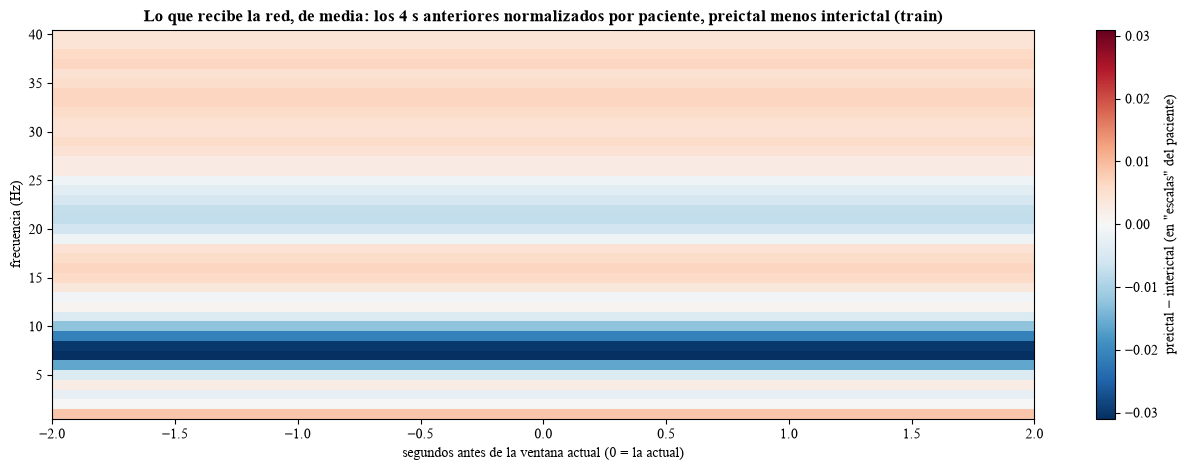

In [11]:
pos_entrena = np.where(en_entrena)[0]
suma = {0: np.zeros((K_RED, N_FRECUENCIAS)), 1: np.zeros((K_RED, N_FRECUENCIAS))}
for a in range(0, len(pos_entrena), 2048):
    x, yy = datos.lote(pos_entrena[a:a + 2048])
    media_canales = x.mean(dim=2).cpu().numpy()                          # (lote, k, frecuencias)
    yy = yy.cpu().numpy()
    for e in (0, 1):
        suma[e] += media_canales[yy == e].sum(axis=0)
diferencia_secuencia = suma[1] / max((y[en_entrena] == 1).sum(), 1) - suma[0] / max((y[en_entrena] == 0).sum(), 1)
segundos = -VENTANA_S * np.arange(K_RED - 1, -1, -1)
limite = np.nanmax(np.abs(diferencia_secuencia)) or 1
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(13, 4.8))
    imagen = ax.imshow(diferencia_secuencia.T, aspect='auto', origin='lower', cmap='RdBu_r', vmin=-limite, vmax=limite,
                       extent=[segundos[0] - VENTANA_S / 2, segundos[-1] + VENTANA_S / 2, FRECUENCIAS[0] - 0.5, FRECUENCIAS[-1] + 0.5])
    plt.colorbar(imagen, ax=ax, label='preictal − interictal (en "escalas" del paciente)')
    ax.set_xlabel('segundos antes de la ventana actual (0 = la actual)')
    ax.set_ylabel('frecuencia (Hz)')
    ax.set_title(f'Lo que recibe la red, de media: los {CONTEXTO_S} s anteriores normalizados por paciente, preictal menos interictal (train)',
                 fontsize=12, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'entrada_media_red.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Cada columna es una de las ventanas de 4 s de la secuencia (a la derecha, la actual) y cada fila, una frecuencia. El color es cuánto se aparta, de media, la ⏳ de la 💤 **respecto a lo normal en su paciente** (media de los 22 canales): rojo = más energía relativa en ⏳, azul = menos, blanco = igual.

✅ **Qué deberías ver:** colores más intensos que en la figura de §4 (la normalización por paciente hace aflorar diferencias que la media entre pacientes tapaba). Si el patrón es parecido en todas las columnas, lo que cuenta es el **nivel** del minuto; si cambia de izquierda a derecha, hay **tendencia**, que es justo lo que puede aprovechar la GRU.

## 6. La red: una CNN para cada ventana y una GRU para el minuto

> 🎯 **Qué hacemos:** crear la red y comprobar que un lote pasa por ella con las formas esperadas.
>
> 🤔 **Por qué esta arquitectura:** la CNN es el punto de partida estándar para resumir el EEG (aprende filtros parecidos a bandas); la GRU es la forma más sencilla y estable de leer una secuencia corta (15 pasos) con pocos pacientes. LSTM, Transformer y la red de grafos de Tang et al. quedan como variantes para comparar después: cambiar la GRU por otra cosa es tocar una sola pieza (`tfm_comun/red/redes/cnn_gru.py`).

![La red](img/arquitectura_cnn_gru.png)

👀 **Qué enseña.** Arriba, las 15 ventanas del último minuto (a la derecha, la actual), ya normalizadas por paciente. Cada una pasa por **la misma** CNN, que la resume en 64 números. La GRU lee esos 15 resúmenes en orden y su memoria final pasa por una capa que da la probabilidad de ⏳. La variante **sin contexto** es la misma red con una sola ventana.

![Qué hace la GRU en cada paso](img/gru_por_dentro.png)

👀 **Qué enseña.** Un paso de la GRU por dentro. Entra la memoria de antes y el resumen de la ventana nueva; la **puerta de actualización z** decide cuánto se conserva y cuánto se reescribe. Abajo, cómo se diferencia de la RNN simple y de la LSTM.

In [12]:
fijar_semillas(SEMILLA)
red_ejemplo = crear_red(N_CANALES, N_FRECUENCIAS).to(dispositivo)
parametros = contar_parametros(red_ejemplo)
x, yy = datos.lote(np.arange(min(8, len(filas))))
with torch.no_grad():
    red_ejemplo.eval()
    resumenes = red_ejemplo.resumir_ventanas(x)
    salida = red_ejemplo(x)
formas = pd.DataFrame([
    ('entrada (un lote de 8 filas)', tuple(x.shape), 'filas × ventanas × canales × frecuencias'),
    ('resumen de cada ventana (CNN)', tuple(resumenes.shape), 'filas × ventanas × 64 números'),
    ('salida (logit)', tuple(salida.shape), 'un número por fila; sigmoid(logit) = probabilidad de ⏳'),
], columns=['paso', 'forma', 'qué es']).set_index('paso')
display(formas)
tabla_parametros = pd.DataFrame({'parámetros': parametros}).rename(index={'codificador': 'CNN (codificador de ventana)', 'gru': 'GRU',
                                                                          'final': 'capa final', 'total': 'total'})
tabla_parametros.index.name = 'pieza'
display(con_separadores(tabla_parametros, decimales=0))
del red_ejemplo

,forma,qué es
paso,,
entrada (un lote de 8 filas),"(8, 1, 22, 40)",filas × ventanas × canales × frecuencias
resumen de cada ventana (CNN),"(8, 1, 64)",filas × ventanas × 64 números
salida (logit),"(8,)",un número por fila; sigmoid(logit) = probabili...


,parámetros
pieza,
CNN (codificador de ventana),25.920
GRU,24.960
capa final,65
total,50.945


👀 **Cómo leer las tablas.** Arriba, la forma de los datos en cada paso (con 8 filas de ejemplo). Abajo, cuántos números aprende cada pieza.

✅ **Qué deberías ver:** entrada `(8, 15, 22, 40)`, resúmenes `(8, 15, 64)` y salida `(8,)`. Unos 50.000 parámetros: pocos para una red, a propósito (hay unos 80 pacientes en 🔵 train).

## 7. Entrenar: tres variantes, tres semillas, parada temprana

> 🎯 **Qué hacemos:** entrenar cada variante con 3 semillas. En cada entrenamiento, la red aprende con 🔵 train y al final de cada época se mide en 🟡 dev; se queda la **mejor época**. Se guardan los pesos de cada red en `modelos/`.
>
> 🤔 **Por qué tres semillas:** con otra semilla la misma red puede salir ±0,02 de AUC. Promediando las 3 (un **conjunto** o *ensemble* de 3 redes) la nota es más estable, y la tabla enseña cuánto varía.

![Un paso de entrenamiento](img/un_paso_de_entrenamiento.png)

*Arriba: los 7 pasos que se repiten con cada lote (`tfm_comun/red/entreno/entrenar_red.py`). Abajo: cuándo se para.*

![Parada temprana](img/parada_temprana.png)

👀 **Qué enseña.** Cómo se ve un entrenamiento: la pérdida de train (negro) baja siempre; la AUC de dev (rojo) sube, se estanca y baja cuando la red empieza a aprenderse a los pacientes de train. Se guarda la red del punto rojo y se para tras 6 épocas sin mejorar.

> 💡 Con GPU, cada entrenamiento tarda del orden de **1-3 minutos** (los espectros ya están en la tarjeta). En el procesador, bastante más.

In [13]:
puntuaciones_semilla, historiales, resumen_entrenamiento = {}, [], []
inicio_total = time.time()
for nombre, variante in VARIANTES.items():
    P = np.full((N_SEMILLAS, len(filas)), np.nan)
    for s in range(N_SEMILLAS):
        semilla = SEMILLA + s
        for ronda, entrena, valida in rondas:
            pos_e, pos_v = np.where(entrena)[0], np.where(valida)[0]
            fijar_semillas(semilla)                                    # mismos pesos iniciales con la misma semilla
            red = crear_red(N_CANALES, N_FRECUENCIAS).to(dispositivo)
            pesos = peso_por_paciente(pacientes[pos_e]) if variante['mismo_peso'] else None
            inicio = time.time()
            red, historial, mejor = entrenar_red(red, datos, pos_e, pos_v, k=variante['k'], semilla=semilla, pesos=pesos, ajustes=AJUSTES,
                                                 progreso=lambda it: tqdm(it, desc=f'{nombre} · semilla {semilla} · {ronda}', leave=False))
            P[s, pos_v] = puntuar_red(red, datos, pos_v, k=variante['k'])
            ruta_modelo = RUTA_MODELOS / f'{nombre}_semilla{semilla}_{nombre_fichero(ronda)}.pt'
            torch.save({'estado': red.state_dict(), 'arquitectura': ARQUITECTURA, 'k': variante['k'], 'n_canales': N_CANALES,
                        'n_frecuencias': N_FRECUENCIAS, 'frecuencias_hz': FRECUENCIAS.tolist(), 'normalizacion': NORMALIZACION,
                        'mejor_epoca': mejor['epoca'], 'auc_validacion': mejor['auc_validacion'], 'conjunto': CONJUNTO}, ruta_modelo)
            historiales.append(historial.reset_index().assign(variante=nombre, semilla=semilla, ronda=ronda))
            resumen_entrenamiento.append({'variante': nombre, 'semilla': semilla, 'ronda': ronda, 'mejor época': mejor['epoca'],
                                          'épocas entrenadas': len(historial), 'AUC en dev (mejor época)': mejor['auc_validacion'],
                                          'minutos': (time.time() - inicio) / 60})
    puntuaciones_semilla[nombre] = P
historial_todo = pd.concat(historiales, ignore_index=True)
tabla_entrenamiento = pd.DataFrame(resumen_entrenamiento).set_index(['variante', 'semilla', 'ronda'])
display(con_separadores(tabla_entrenamiento, decimales=3))
print(f'{len(tabla_entrenamiento)} entrenamientos en {numero_legible(round((time.time() - inicio_total) / 60, 1))} min · '
      f'modelos guardados en {RUTA_MODELOS.relative_to(RUTA_OUTPUTS_FASE_03.parent)}')

red_4s · semilla 42 · 🟡 dev:   0%|          | 0/40 [00:00<?, ?it/s]

red_4s · semilla 43 · 🟡 dev:   0%|          | 0/40 [00:00<?, ?it/s]

red_4s · semilla 44 · 🟡 dev:   0%|          | 0/40 [00:00<?, ?it/s]

red_4s_mismo_peso · semilla 42 · 🟡 dev:   0%|          | 0/40 [00:00<?, ?it/s]

red_4s_mismo_peso · semilla 43 · 🟡 dev:   0%|          | 0/40 [00:00<?, ?it/s]

red_4s_mismo_peso · semilla 44 · 🟡 dev:   0%|          | 0/40 [00:00<?, ?it/s]

6 entrenamientos en 1,2 min · modelos guardados en fase_03\04_red_prediccion\modelos


👀 **Cómo leer la tabla.** Una fila por variante, semilla y ronda de validación: en qué época se quedó la mejor red, cuántas épocas se entrenaron (la mejor + la paciencia, si paró antes del máximo), su AUC en 🟡 dev y cuánto tardó.

✅ **Qué deberías ver:** AUC parecidas entre semillas de la misma variante (diferencias de 0,01-0,03 son normales). Si la mejor época es casi siempre la 1 o la 2, la red se sobreajusta muy deprisa y habría que hacerla más pequeña o con más dropout. Si coincide con el máximo de épocas, aún estaba aprendiendo: habría que subir `epocas_max`.

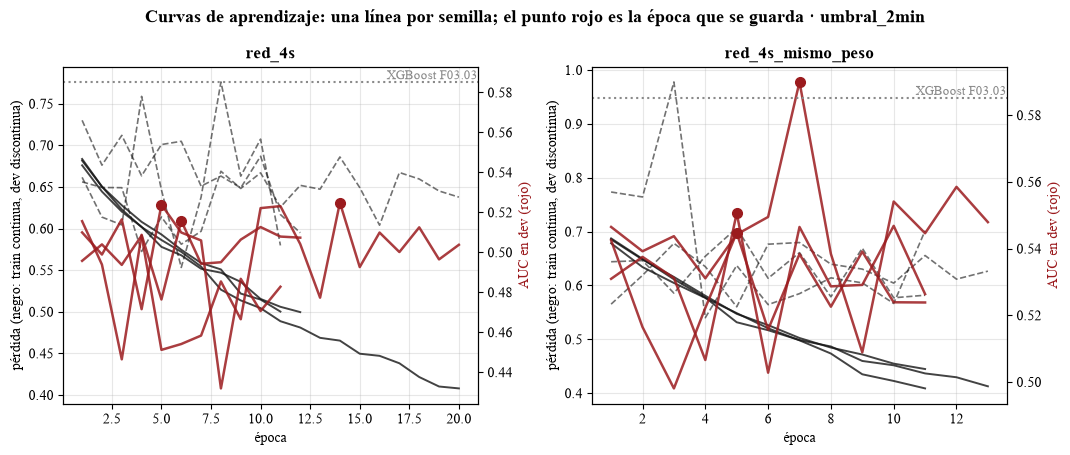

In [14]:
# Figura: las curvas de aprendizaje de cada variante (una línea por semilla)
variantes = list(VARIANTES)
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(variantes), figsize=(5.4 * len(variantes), 4.6), sharey=False)
    axes = np.atleast_1d(axes)
    for ax, nombre in zip(axes, variantes):
        ax2 = ax.twinx()
        for (semilla, ronda), h in historial_todo[historial_todo.variante == nombre].groupby(['semilla', 'ronda']):
            ax.plot(h['época'], h['pérdida train'], color=COLORES_ESQUEMA['negro'], lw=1.4, alpha=0.8)
            ax.plot(h['época'], h['pérdida validación'], color=COLORES_ESQUEMA['negro'], lw=1.2, ls='--', alpha=0.6)
            ax2.plot(h['época'], h['AUC validación'], color=COLORES_ESQUEMA['rojo'], lw=1.8, alpha=0.85)
            mejor_fila = h.loc[h['AUC validación'].idxmax()]
            ax2.plot(mejor_fila['época'], mejor_fila['AUC validación'], 'o', color=COLORES_ESQUEMA['rojo'], ms=7)
        ax2.axhline(AUC_XGB, color=COLORES_ESQUEMA['gris'], ls=':', lw=1.5)
        ax2.text(ax.get_xlim()[1], AUC_XGB, ' XGBoost F03.03', color=COLORES_ESQUEMA['gris'], fontsize=9, va='bottom', ha='right')
        ax.set_xlabel('época')
        ax.set_ylabel('pérdida (negro: train continua, dev discontinua)')
        ax2.set_ylabel('AUC en dev (rojo)', color=COLORES_ESQUEMA['rojo'])
        ax.set_title(nombre, fontsize=12, fontweight='bold')
        ax.grid(alpha=0.3)
    fig.suptitle(f'Curvas de aprendizaje: una línea por semilla; el punto rojo es la época que se guarda · {CONJUNTO}', fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'curvas_aprendizaje.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Un panel por variante y una línea por semilla. Negro continuo: la pérdida en train (eje izquierdo); negro discontinuo: la pérdida en dev. Rojo: la AUC en dev (eje derecho), con un punto en la época que se guarda. La línea gris de puntos es la AUC de XGBoost de F03.03.

✅ **Qué deberías ver:** la pérdida de train bajando siempre y la de dev bajando al principio y subiendo después (el **sobreajuste**). La AUC roja debería tocar o pasar la línea gris si la red supera a XGBoost. Si las semillas van muy separadas, el resultado depende mucho del azar.

## 8. La nota en dev, ventana a ventana, frente a XGBoost

> 🎯 **Qué hacemos:** juntar las 3 semillas de cada variante (media de sus probabilidades) y medir todas las redes y los modelos de F03.02-F03.03 con **las mismas ventanas** de 🟡 dev y las mismas métricas. Se añade una quinta fila: **red + XGBoost** (la media de sus rangos), por si se complementan.
>
> 🤔 **Por qué ventana a ventana:** F03.03 guardó la puntuación de XGBoost en cada ventana de dev (`puntuaciones_validacion.csv`). Comparar con las mismas ventanas permite la **diferencia emparejada** de §9, mucho más fina que comparar dos intervalos.

In [15]:
puntos_03 = pd.read_csv(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'puntuaciones_validacion.csv').set_index('id_ventana')
en_03 = filas.id_ventana.isin(puntos_03.index).to_numpy()
comun = validar & en_03
p_xgb, p_base = np.full(len(filas), np.nan), np.full(len(filas), np.nan)
p_xgb[comun] = puntos_03.loc[filas.id_ventana[comun], 'puntuacion_mejor'].to_numpy()
p_base[comun] = puntos_03.loc[filas.id_ventana[comun], 'puntuacion_linea_base_4s'].to_numpy()
print(f'Ventanas de validación con puntuación de F03.03: {numero_legible(int(comun.sum()))} de {numero_legible(int(validar.sum()))}'
      + ('' if comun.sum() == validar.sum() else ' 🔴 (no son todas: se compara solo con las comunes)'))

p_red = {}
for nombre, P in puntuaciones_semilla.items():                         # media de las semillas (solo hay puntuación en validación)
    p_red[nombre] = np.full(len(filas), np.nan)
    p_red[nombre][validar] = P[:, validar].mean(axis=0)
def rangos(p):   # de 0 a 1 según el orden; para juntar modelos con escalas distintas
    r = np.full(len(p), np.nan)
    r[comun] = rankdata(p[comun]) / comun.sum()
    return r
MEZCLA = f'red + XGBoost (media de rangos)'
modelos = {'línea base F03.02 (XGBoost, 4 s)': p_base, NOMBRE_XGB: p_xgb, **{f'🧠 {n}': p for n, p in p_red.items()},
           MEZCLA: (rangos(p_red[PRINCIPAL]) + rangos(p_xgb)) / 2}

filas_res = {}
for nombre, p in modelos.items():
    auc, inferior, superior = auroc_con_intervalo(y[comun], p[comun], pacientes[comun], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    pp = auroc_por_paciente(y[comun], p[comun], pacientes[comun])
    variante = nombre.replace('🧠 ', '')
    por_semilla = ([float(auroc_con_intervalo(y[comun], P[comun], pacientes[comun], n_bootstrap=1, semilla=SEMILLA)[0]) for P in puntuaciones_semilla[variante]]
                   if variante in puntuaciones_semilla else [])
    filas_res[nombre] = {'AUC-ROC': auc, 'IC 95 % (por paciente)': f'{decimal(inferior)} – {decimal(superior)}',
                         f'sensibilidad con especificidad {numero_legible(100 * ESPECIFICIDAD)} %': sensibilidad_con_especificidad(y[comun], p[comun], ESPECIFICIDAD)[0],
                         'AUC por paciente (mediana)': float(pp.auroc.median()) if len(pp) else np.nan,
                         'AUC de cada semilla': ' · '.join(decimal(a) for a in por_semilla) if por_semilla else '—',
                         '_inferior': inferior, '_superior': superior}
resultados = pd.DataFrame(filas_res).T.infer_objects()
resultados.index.name = 'modelo'
display(con_separadores(resultados.drop(columns=['_inferior', '_superior']), decimales=3))

Ventanas de validación con puntuación de F03.03: 52.464 de 52.464


,AUC-ROC,IC 95 % (por paciente),sensibilidad con especificidad 90 %,AUC por paciente (mediana),AUC de cada semilla
modelo,,,,,
"línea base F03.02 (XGBoost, 4 s)","0,543","0,48 – 0,59","0,100","0,549",—
"XGBoost F03.03 (16 s, por_paciente_calibrado)","0,585","0,54 – 0,65","0,134","0,619",—
🧠 red_4s,"0,528","0,47 – 0,61","0,117","0,536","0,52 · 0,52 · 0,52"
🧠 red_4s_mismo_peso,"0,573","0,53 – 0,63","0,111","0,580","0,59 · 0,54 · 0,55"
red + XGBoost (media de rangos),"0,580","0,53 – 0,66","0,138","0,599",—


👀 **Cómo leer la tabla.** Una fila por modelo, todos medidos con las mismas ventanas de 🟡 dev. Las dos primeras son de F03.02 y F03.03 (su puntuación guardada); las que llevan 🧠 son las redes de este notebook (media de las 3 semillas; la última columna da la AUC de cada semilla por separado); la última, la mezcla de la red principal con XGBoost.

✅ **Qué deberías ver:** la red principal cerca o por encima de XGBoost de F03.03, y por encima de la red de 4 s si el contexto le sirve. Si la mezcla sale por encima de los dos, la red y XGBoost aciertan en ventanas **distintas** y se complementan.

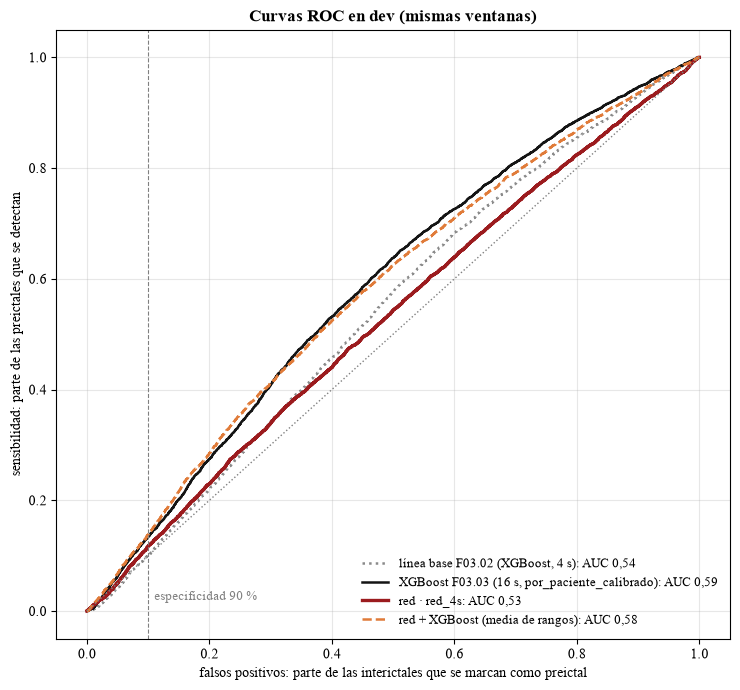

In [16]:
# Figura: curvas ROC de los modelos principales
dibujar = ['línea base F03.02 (XGBoost, 4 s)', NOMBRE_XGB] + [f'🧠 {n}' for n in [PRINCIPAL, SIN_CONTEXTO] if n] + [MEZCLA]
estilos = {dibujar[0]: (COLORES_ESQUEMA['gris'], ':'), dibujar[1]: (COLORES_ESQUEMA['negro'], '-'), f'🧠 {PRINCIPAL}': (COLORES_ESQUEMA['rojo'], '-'),
           MEZCLA: ('#e07b39', '--')}
if SIN_CONTEXTO:
    estilos[f'🧠 {SIN_CONTEXTO}'] = (COLORES_ESQUEMA['rojo'], ':')
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(7.5, 7))
    for nombre in dibujar:
        fpr, tpr, _ = roc_curve(y[comun], modelos[nombre][comun])
        color, estilo = estilos[nombre]
        ax.plot(fpr, tpr, color=color, ls=estilo, lw=2.4 if 'red_' in nombre and 'mismo' not in nombre and estilo == '-' else 1.8,
                label=f'{nombre.replace("🧠 ", "red · ")}: AUC {decimal(resultados.loc[nombre, "AUC-ROC"])}')
    ax.plot([0, 1], [0, 1], color='gray', lw=1, ls=':')
    ax.axvline(1 - ESPECIFICIDAD, color='gray', lw=0.8, ls='--')
    ax.text(1 - ESPECIFICIDAD + 0.01, 0.02, f'especificidad {numero_legible(100 * ESPECIFICIDAD)} %', color='gray', fontsize=9)
    ax.set_xlabel('falsos positivos: parte de las interictales que se marcan como preictal')
    ax.set_ylabel('sensibilidad: parte de las preictales que se detectan')
    ax.set_title('Curvas ROC en dev (mismas ventanas)', fontsize=12, fontweight='bold')
    ax.legend(frameon=False, fontsize=9.5, loc='lower right')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'curvas_roc_dev.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Cada curva recorre todos los umbrales posibles de un modelo: hacia arriba, más ⏳ detectadas; hacia la derecha, más 💤 marcadas por error. Cuanto más arriba a la izquierda, mejor; la diagonal es el azar. La línea vertical marca el punto de la tabla (especificidad del 90 %). Rojo continuo: la red principal; negro: XGBoost de F03.03.

✅ **Qué deberías ver:** la roja por encima de la negra, sobre todo en la parte izquierda (pocos falsos positivos), que es la que importa para una alarma.

## 9. ¿La red supera a XGBoost? (diferencia emparejada)

> 🎯 **Qué hacemos:** comparar con **diferencia emparejada** (mismas ventanas, mismos sorteos de pacientes): la red principal frente a XGBoost de F03.03, frente a sí misma sin contexto y frente a la variante de mismo peso por paciente; y la mezcla frente a XGBoost.
>
> 🤔 **Por qué:** dos intervalos que se solapan no dicen si una mejora es real; la diferencia emparejada sí (si su intervalo no incluye el 0). Y, como en F03.03, una mejora real menor que `MEJORA_MINIMA` no compensa la complejidad.

In [17]:
def comparar(a, b):
    return diferencia_auroc_con_intervalo(y[comun], modelos[a][comun], modelos[b][comun], pacientes[comun], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)

parejas = [(f'🧠 {PRINCIPAL}', NOMBRE_XGB, 'la red frente a XGBoost (la pregunta principal)')]
if SIN_CONTEXTO:
    parejas.append((f'🧠 {PRINCIPAL}', f'🧠 {SIN_CONTEXTO}', f'¿le sirven a la red los {CONTEXTO_S} s?'))
parejas += [(f'🧠 {MISMO_PESO}', f'🧠 {PRINCIPAL}', '¿ayuda dar el mismo peso a cada paciente?'),
            (MEZCLA, NOMBRE_XGB, '¿se complementan la red y XGBoost?')]
diferencias = {}
filas_comp = []
for a, b, pregunta in parejas:
    d = comparar(a, b)
    diferencias[(a, b)] = d
    filas_comp.append({'pregunta': pregunta, 'A': a.replace('🧠 ', 'red · '), 'B': b.replace('🧠 ', 'red · '),
                       'diferencia de AUC (A − B)': con_signo(d[0]), 'IC 95 %': f'{decimal(d[1], 3)} – {decimal(d[2], 3)}', 'lectura': lectura_diferencia(d, MEJORA_MINIMA)})
comparacion = pd.DataFrame(filas_comp).set_index('pregunta')

d_principal = diferencias[(f'🧠 {PRINCIPAL}', NOMBRE_XGB)]
auc_red, inf_red, sup_red = resultados.loc[f'🧠 {PRINCIPAL}', ['AUC-ROC', '_inferior', '_superior']]
if d_principal[1] > 0 and d_principal[0] >= MEJORA_MINIMA:
    veredicto = ('✅ La red supera a XGBoost', 'la red pasa a ser el modelo de referencia de la fase')
elif d_principal[2] < 0:
    veredicto = ('🔴 La red queda por debajo de XGBoost', 'con estos datos, XGBoost con el contexto resumido sigue siendo mejor: antes de complicar la red, revisar §7 (sobreajuste) y probar variantes')
else:
    sentido = 'por encima' if d_principal[0] > 0 else 'por debajo'
    veredicto = ('🟡 Sin diferencia clara con XGBoost',
                 f'la red queda {sentido} ({con_signo(d_principal[0])}), pero el intervalo incluye el 0: con estos pacientes no se puede decir cuál es mejor. '
                 'La red llega cerca aprendiendo sola lo que en F03.03 se diseñó a mano; para superarlo hacen falta variantes (más contexto, señal en bruto, grafos)')
if MODO_PRUEBA:
    veredicto = ('🔴 MODO PRUEBA · ' + veredicto[0], veredicto[1] + ' (cifras sin valor: 10 % de las ventanas, 1 semilla, 2 épocas)')
mostrar_destacado(f'{veredicto[0]}',
                  f'Red principal ({CONTEXTO_S} s, {NORMALIZACION}, media de {N_SEMILLAS} semillas): <b>AUC {con_intervalo(auc_red, inf_red, sup_red)}</b> · '
                  f'{NOMBRE_XGB}: <b>{decimal(resultados.loc[NOMBRE_XGB, "AUC-ROC"])}</b> · diferencia <b>{con_signo(d_principal[0])}</b> '
                  f'(IC {decimal(d_principal[1], 3)} – {decimal(d_principal[2], 3)}).', comparacion, f'<b>Qué significa:</b> {veredicto[1]}.')

KeyboardInterrupt: 

👀 **Cómo leer el recuadro.** Arriba, el veredicto de la pregunta principal con las dos notas y su diferencia. La tabla responde, con el mismo método, a las cuatro preguntas: cada fila compara A con B; si el intervalo no incluye el 0, la diferencia es real.

✅ **Qué deberías ver:** cuál de las tres situaciones se da (✅ supera, 🟡 empata, 🔴 queda por debajo). Un **empate** ya es un resultado útil para la memoria: la red llega sola, desde el espectro, a lo que XGBoost necesitó con un resumen diseñado a mano; y es la base para las variantes siguientes. Si la red de 60 s **no** mejora a la de 4 s, la red no está aprovechando el minuto.

## 10. Por paciente y por grupo de crisis

> 🎯 **Qué hacemos:** (1) la AUC **dentro de cada paciente** de 🟡 dev para la red principal y para XGBoost, enfrentadas; (2) la AUC por **grupo de inicio** (⏳ de ese grupo frente a todas las 💤).
>
> 🤔 **Por qué:** una AUC global buena puede venir de unos pocos pacientes muy fáciles. Para una app, importa en **cuántos** pacientes funciona.

In [ ]:
pp_red = auroc_por_paciente(y[comun], modelos[f'🧠 {PRINCIPAL}'][comun], pacientes[comun])
pp_xgb = auroc_por_paciente(y[comun], p_xgb[comun], pacientes[comun])
por_paciente = pp_red[['auroc', '⏳ preictal', '💤 interictal']].rename(columns={'auroc': 'AUC red'}).join(pp_xgb[['auroc']].rename(columns={'auroc': 'AUC XGBoost'}))
por_paciente['red − XGBoost'] = por_paciente['AUC red'] - por_paciente['AUC XGBoost']
por_paciente = por_paciente.sort_values('AUC red', ascending=False)
gana_red = int((por_paciente['red − XGBoost'] > 0).sum())
sobre_azar = {m: int((por_paciente[f'AUC {m}'] > 0.5).sum()) for m in ['red', 'XGBoost']}

grupos = [g for g in ['focal', 'generalizada', 'ausencia'] if g in set(filas.grupo[comun & (y == 1)].dropna())]
filas_grupo = {}
for g in grupos:
    m = comun & ((y == 0) | (filas.grupo.to_numpy() == g))
    fila = {'pacientes con ⏳': len(set(pacientes[m & (y == 1)]))}
    for etiqueta, p in [('red', modelos[f'🧠 {PRINCIPAL}']), ('XGBoost', p_xgb)]:
        a, i_, s_ = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        fila[f'AUC {etiqueta}'] = a
        fila[f'IC {etiqueta}'] = f'{decimal(i_)} – {decimal(s_)}'
    filas_grupo[con_icono(g)] = fila
por_grupo = pd.DataFrame(filas_grupo).T.infer_objects()
por_grupo.index.name = 'grupo de inicio'
if len(por_grupo):
    display(Markdown('**AUC en dev por grupo de inicio** (⏳ de ese grupo frente a todas las 💤)'))
    display(con_separadores(por_grupo, decimales=3))

with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(7, 7))
    tam = 20 + 180 * por_paciente['⏳ preictal'] / por_paciente['⏳ preictal'].max()
    ax.scatter(por_paciente['AUC XGBoost'], por_paciente['AUC red'], s=tam, color=COLORES_ESQUEMA['rojo'], alpha=0.65, edgecolor=COLORES_ESQUEMA['negro'])
    ax.plot([0, 1], [0, 1], color='gray', lw=1)
    ax.axhline(0.5, color='gray', lw=0.8, ls=':')
    ax.axvline(0.5, color='gray', lw=0.8, ls=':')
    ax.text(0.03, 0.96, f'la red gana en {gana_red} de {len(por_paciente)} pacientes', transform=ax.transAxes, fontsize=11, fontweight='bold', va='top')
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel(f'AUC dentro del paciente · {NOMBRE_XGB}')
    ax.set_ylabel(f'AUC dentro del paciente · red {PRINCIPAL}')
    ax.set_title('Paciente a paciente (tamaño = ventanas preictales)', fontsize=12, fontweight='bold')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'auc_por_paciente.png', dpi=150, bbox_inches='tight')
    plt.show()
print(f'Pacientes de dev con las dos clases: {len(por_paciente)} · por encima del azar: red {sobre_azar["red"]}, XGBoost {sobre_azar["XGBoost"]} · '
      f'la red gana en {gana_red}')

👀 **Cómo leer la tabla y la figura.** La tabla da la AUC de la red y de XGBoost para cada grupo de inicio, con sus intervalos. En la figura, cada punto es un paciente de 🟡 dev (más grande = más ventanas ⏳): horizontal, su AUC con XGBoost; vertical, con la red. Por encima de la diagonal, la red ordena mejor sus ventanas; las líneas de puntos marcan el azar (0,5).

✅ **Qué deberías ver:** la mayoría de puntos en el cuadrante de arriba a la derecha (los dos por encima del azar) y más por encima de la diagonal que por debajo si la red es mejor. **Cuidado** con los grupos de pocos pacientes (sobre todo 🔹 ausencia): la cifra seria es la del conjunto `grupo_ausencia`, con validación cruzada.

## 11. Control de sesión: ¿predice la crisis o reconoce la grabación?

> 🎯 **Qué hacemos:** repetir la nota en 🟡 dev comparando las ⏳ solo con 💤 de **las mismas sesiones** (y de los mismos ficheros) de su paciente, como en F03.03 §10 (`tfm_comun/prediccion/control_sesion.py`). No se reentrena nada.
>
> 🤔 **Por qué:** una red es mucho más capaz que XGBoost de aprender pistas tramposas. Si la red supera a XGBoost en §9 pero **cae** aquí, su ventaja venía de reconocer la grabación, no de predecir.

![El control de sesión](img/control_sesion_esquema.png)

👀 **Qué enseña.** (La imagen de F03.03.) Un paciente con tres grabaciones; solo la del lunes tiene crisis. El control de *misma sesión* compara sus ⏳ solo con 💤 del lunes.

In [ ]:
controles = controles_de_sesion(comun, y, pacientes, filas.file.to_numpy())
filas_control, notas_control = {}, {}
for nombre_control, m in controles.items():
    if (y[m] == 0).sum() == 0 or (y[m] == 1).sum() == 0:
        continue
    fila = {'pacientes con las dos clases': len({p for p in set(pacientes[m]) if len(set(y[m & (pacientes == p)])) == 2}),
            '⏳ preictal': int((y[m] == 1).sum()), '💤 interictal': int((y[m] == 0).sum())}
    for etiqueta, p in [('red', modelos[f'🧠 {PRINCIPAL}']), ('XGBoost', p_xgb)]:
        a, i_, s_ = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        fila[f'AUC {etiqueta}'], fila[f'IC {etiqueta}'] = a, f'{decimal(i_)} – {decimal(s_)}'
        notas_control[(nombre_control, etiqueta)] = (a, i_, s_)
    d = diferencia_auroc_con_intervalo(y[m], modelos[f'🧠 {PRINCIPAL}'][m], p_xgb[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    fila['red − XGBoost'], fila['IC de la diferencia'] = con_signo(d[0]), f'{decimal(d[1], 3)} – {decimal(d[2], 3)}'
    notas_control[(nombre_control, 'diferencia')] = d
    filas_control[nombre_control] = fila
control_sesion = pd.DataFrame(filas_control).T.infer_objects()
control_sesion.index.name = 'qué 💤 se usan'

if ('misma sesión', 'red') in notas_control:
    auc_ses, inf_ses, _ = notas_control[('misma sesión', 'red')]
    if inf_ses > 0.5 and auc_ses >= auc_red - 0.05:
        veredicto_sesion = ('✅ Se mantiene: la red predice la crisis, no la grabación',
                            f'Con solo 💤 de las mismas sesiones, la red da <b>AUC {decimal(auc_ses)}</b> (con todas las 💤: {decimal(auc_red)}).')
    elif inf_ses > 0.5:
        veredicto_sesion = ('🟡 Se mantiene en parte',
                            f'Con solo 💤 de las mismas sesiones baja a <b>AUC {decimal(auc_ses)}</b> (con todas: {decimal(auc_red)}), aunque sigue por encima del azar: '
                            'parte de lo que aprende es la grabación.')
    else:
        veredicto_sesion = ('🔴 No se mantiene: la red reconoce la grabación',
                            f'Con solo 💤 de las mismas sesiones cae a <b>AUC {decimal(auc_ses)}</b>, con un intervalo que incluye el azar.')
else:
    veredicto_sesion = ('— Sin control de sesión', 'No hay ⏳ y 💤 de las mismas sesiones en dev.')
mostrar_destacado(f'Control de sesión: {veredicto_sesion[0]}', veredicto_sesion[1], control_sesion)

with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(10, 4.6))
    nombres_c = list(filas_control)
    x = np.arange(len(nombres_c))
    for desplazamiento, etiqueta, color in [(-0.18, 'XGBoost', COLORES_ESQUEMA['negro']), (0.18, 'red', COLORES_ESQUEMA['rojo'])]:
        a = np.array([notas_control[(c, etiqueta)][0] for c in nombres_c])
        i_ = np.array([notas_control[(c, etiqueta)][1] for c in nombres_c])
        s_ = np.array([notas_control[(c, etiqueta)][2] for c in nombres_c])
        ax.bar(x + desplazamiento, a, width=0.34, color=color, alpha=0.85, label=etiqueta if etiqueta == 'red' else NOMBRE_XGB)
        ax.errorbar(x + desplazamiento, a, yerr=[a - i_, s_ - a], fmt='none', ecolor='gray', capsize=4)
    ax.axhline(0.5, color='gray', ls=':', lw=1.2)
    ax.set_xticks(x, [n.replace('💤', 'interictales') for n in nombres_c])
    ax.set_ylim(0.3, 1.02)
    ax.set_ylabel('AUC en dev')
    ax.set_title('Control de sesión: la misma nota quitando la pista de la grabación (barra = intervalo del 95 %)', fontsize=12, fontweight='bold')
    ax.legend(frameon=False)
    ax.grid(alpha=0.3, axis='y')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'control_sesion.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer el recuadro y la figura.** Una fila (y una pareja de barras) por control: con todas las 💤, con las de la misma sesión y con las del mismo fichero. Para cada uno: la AUC de la red y la de XGBoost con sus intervalos, y la diferencia emparejada entre las dos. Arriba, el veredicto con el control de **misma sesión**:

- ✅ la red sigue cerca de su nota (a menos de 0,05) y por encima del azar: **predice la crisis**;
- 🟡 baja bastante, pero sigue por encima del azar: parte de lo que aprende es la grabación;
- 🔴 cae al azar: la red reconocía la grabación.

✅ **Qué deberías ver:** la barra roja aguantando en *misma sesión*. En *mismo fichero* es normal que todo baje (control muy duro: muchas 💤 son de después de la crisis).

## 12. El resultado → tablas, puntuaciones y `configuracion.json`

In [ ]:
resultados.drop(columns=['_inferior', '_superior']).assign(ic_inferior=resultados._inferior, ic_superior=resultados._superior).reset_index().to_csv(
    RUTA_RESULTADOS / 'resultados_dev.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'resultados_dev.csv', 'una fila por modelo (redes, XGBoost de F03.03, línea base y la mezcla): AUC en 🟡 dev con las mismas ventanas, '
                'su intervalo, la sensibilidad con especificidad fija, la AUC por paciente y la de cada semilla')
comparacion.reset_index().to_csv(RUTA_RESULTADOS / 'comparacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'comparacion.csv', 'las diferencias emparejadas de §9 (la red frente a XGBoost, sin contexto, mismo peso y la mezcla)')
historial_todo.to_csv(RUTA_RESULTADOS / 'historial_entrenamiento.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'historial_entrenamiento.csv', 'una fila por época de cada entrenamiento: pérdidas de train y dev, AUC en dev, tasa de aprendizaje y segundos')
por_paciente.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_paciente.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'auc_por_paciente.csv', 'una fila por paciente de 🟡 dev: AUC dentro del paciente con la red y con XGBoost')
control_sesion.reset_index().to_csv(RUTA_RESULTADOS / 'control_sesion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'control_sesion.csv', 'el control de sesión (§11): AUC de la red y de XGBoost con todas las 💤, las de la misma sesión y las del mismo fichero')

puntos = filas.loc[comun, ['id_ventana', 'split', 'patient', 'file', 'clase', 'etiqueta', 'grupo', 'crisis_id']].copy()
for nombre, p in p_red.items():
    puntos[f'puntuacion_{nombre}'] = p[comun].round(5)
puntos['puntuacion_xgboost_f0303'] = p_xgb[comun].round(5)
puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', 'una fila por ventana de 🟡 dev: la probabilidad de ⏳ de cada red (media de las semillas) '
                'y la puntuación de XGBoost de F03.03, para comparar ventana a ventana en los notebooks siguientes')

config = {
    'conjunto': CONJUNTO, 'modo_prueba': MODO_PRUEBA, 'splits_usados': SPLITS, 'eval_usado': False,
    'entrada': {'tipo': 'log10 del espectro relativo por canal (Welch, 1 s)', 'frecuencias_hz': [float(FRECUENCIAS[0]), float(FRECUENCIAS[-1])],
                'canales': N_CANALES, 'contexto_s': CONTEXTO_S, 'ventanas_por_secuencia': K_RED, 'normalizacion': NORMALIZACION},
    'arquitectura': {'tipo': 'CNN por ventana + GRU', **ARQUITECTURA, 'parametros': int(parametros['total'])},
    'entrenamiento': {**AJUSTES, 'n_semillas': N_SEMILLAS, 'semilla_base': SEMILLA},
    'variantes': {n: {'k': v['k'], 'mismo_peso': v['mismo_peso'], 'auc_dev': float(resultados.loc[f'🧠 {n}', 'AUC-ROC'])} for n, v in VARIANTES.items()},
    'principal': {'variante': PRINCIPAL, 'auc_dev': float(auc_red), 'ic95_dev': [float(inf_red), float(sup_red)],
                  'modelos': sorted(str(r.relative_to(RUTA_RESULTADOS)).replace('\\', '/') for r in RUTA_MODELOS.glob(f'{PRINCIPAL}_semilla*.pt'))},
    'frente_a_xgboost': {'auc_xgboost': float(resultados.loc[NOMBRE_XGB, 'AUC-ROC']), 'diferencia': float(d_principal[0]),
                         'ic95_diferencia': [float(d_principal[1]), float(d_principal[2])], 'veredicto': veredicto[0]},
    'contexto_en_la_red': ({'diferencia_60s_menos_4s': float(diferencias[(f'🧠 {PRINCIPAL}', f'🧠 {SIN_CONTEXTO}')][0]),
                            'ic95': [float(v) for v in diferencias[(f'🧠 {PRINCIPAL}', f'🧠 {SIN_CONTEXTO}')][1:]]} if SIN_CONTEXTO else None),
    'control_sesion': {'veredicto': veredicto_sesion[0],
                       **({'auc_misma_sesion': float(notas_control[('misma sesión', 'red')][0])} if ('misma sesión', 'red') in notas_control else {})},
    'ventanas_comparadas': int(comun.sum()), 'especificidad': ESPECIFICIDAD, 'n_bootstrap': N_BOOTSTRAP, 'mejora_minima': MEJORA_MINIMA,
    'dispositivo': ficha['dispositivo'], 'versiones': versiones_usadas, 'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, indent=4, ensure_ascii=False), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'la configuración de la red, sus notas, el veredicto frente a XGBoost y dónde están los modelos (lo leerán los notebooks siguientes)')

## 13. Resumen → `summary.txt`

In [ ]:
datos_resumen = [
    f'Red neuronal (CNN + GRU): {config["fecha"]} · conjunto {CONJUNTO} · {N_SEMILLAS} semillas desde la {SEMILLA}' + (' · MODO PRUEBA' if MODO_PRUEBA else ''),
    f'Entrada: espectro relativo 22 × {N_FRECUENCIAS} por ventana · {CONTEXTO_S} s de contexto ({K_RED} ventanas) · normalización {NORMALIZACION}',
    f'{numero_legible(int(comun.sum()))} ventanas de 🟡 dev comparadas con F03.03 · 🟢 eval no usado',
    f'Red principal: AUC {con_intervalo(auc_red, inf_red, sup_red)} · {NOMBRE_XGB}: {decimal(resultados.loc[NOMBRE_XGB, "AUC-ROC"])}',
    f'Frente a XGBoost: {veredicto[0]} ({con_signo(d_principal[0])}; IC {decimal(d_principal[1], 3)} – {decimal(d_principal[2], 3)})',
    f'Control de sesión: {veredicto_sesion[0]}',
]
tablas_resumen = {'Resultados en dev': resultados.drop(columns=['_inferior', '_superior']).round(3), 'Comparaciones emparejadas': comparacion,
                  'Entrenamientos': tabla_entrenamiento.round(3), 'Control de sesión': control_sesion.round(3)}
if len(por_grupo):
    tablas_resumen['Por grupo de inicio'] = por_grupo.round(3)
texto = ('=== F03.04 · La primera red neuronal ===\n' + '\n'.join(datos_resumen) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen de la red en texto')

## 14. Conclusiones

Se escriben solas a partir de los datos al ejecutar la celda.

In [ ]:
conclusiones = [
    f'**1. La red frente a XGBoost.** {veredicto[0]}: la red principal ({CONTEXTO_S} s, {NORMALIZACION}) saca **AUC {con_intervalo(auc_red, inf_red, sup_red)}** '
    f'frente a {decimal(resultados.loc[NOMBRE_XGB, "AUC-ROC"])} de XGBoost ({con_signo(d_principal[0])}, IC {decimal(d_principal[1], 3)} – {decimal(d_principal[2], 3)}): {lectura_diferencia(d_principal, MEJORA_MINIMA)}.',
]
if SIN_CONTEXTO:
    d_ctx = diferencias[(f'🧠 {PRINCIPAL}', f'🧠 {SIN_CONTEXTO}')]
    conclusiones.append(f'**2. El contexto dentro de la red.** Con {CONTEXTO_S} s la red cambia en {con_signo(d_ctx[0])} respecto a la misma red con solo '
                        f'{VENTANA_S} s (IC {decimal(d_ctx[1], 3)} – {decimal(d_ctx[2], 3)}): {lectura_diferencia(d_ctx, MEJORA_MINIMA)}. '
                        + ('La GRU aprovecha el minuto.' if d_ctx[1] > 0 else 'La red no está sacando partido del minuto: casi todo lo aporta la normalización por paciente.'))
d_peso = diferencias[(f'🧠 {MISMO_PESO}', f'🧠 {PRINCIPAL}')]
conclusiones.append(f'**3. Mismo peso por paciente.** {con_signo(d_peso[0])} (IC {decimal(d_peso[1], 3)} – {decimal(d_peso[2], 3)}): {lectura_diferencia(d_peso, MEJORA_MINIMA)}.')
d_mezcla = diferencias[(MEZCLA, NOMBRE_XGB)]
conclusiones.append(f'**4. Red + XGBoost.** La mezcla cambia la AUC de XGBoost en {con_signo(d_mezcla[0])} (IC {decimal(d_mezcla[1], 3)} – {decimal(d_mezcla[2], 3)}): {lectura_diferencia(d_mezcla, MEJORA_MINIMA)}. '
                    + ('Aciertan en ventanas distintas: se complementan.' if d_mezcla[1] > 0 else 'Aprenden casi lo mismo.'))
auc_semillas = tabla_entrenamiento.xs(PRINCIPAL, level='variante')['AUC en dev (mejor época)']
epocas = tabla_entrenamiento['mejor época']
conclusiones.append(f'**5. Estabilidad.** Las {N_SEMILLAS} semillas de la red principal dan AUC entre {decimal(auc_semillas.min())} y {decimal(auc_semillas.max())} '
                    f'en su mejor época; la mejor época va de la {int(epocas.min())} a la {int(epocas.max())}'
                    + (' (muy pronto: la red se sobreajusta enseguida).' if epocas.median() <= 3 else '.'))
conclusiones.append(f'**6. Paciente a paciente.** La red gana a XGBoost en {gana_red} de {len(por_paciente)} pacientes de dev y queda por encima del azar en {sobre_azar["red"]} '
                    f'(XGBoost: {sobre_azar["XGBoost"]}).')
conclusiones.append(f'**7. Control de sesión: {veredicto_sesion[0]}.** ' + re.sub('<[^>]+>', '', veredicto_sesion[1]))
if MODO_PRUEBA:
    conclusiones.insert(0, '🔴 **MODO PRUEBA:** con un 10 % de las ventanas y 2 épocas, estas cifras no tienen valor.')
display(Markdown('\n\n'.join(conclusiones)))

## 15. Qué nos ha enseñado este notebook (y qué viene después)

> 🎯 **Para qué:** dejar escrito, con los datos de esta ejecución, el razonamiento completo. Es la parte que más se usará en la **memoria**.

In [ ]:
pasos_historia = pd.DataFrame([
    ('F03.02 · ventana de 4 s sola (XGBoost)', decimal(resultados.loc['línea base F03.02 (XGBoost, 4 s)', 'AUC-ROC']), 'casi el azar'),
    (f'F03.03 · {NOMBRE_XGB}', decimal(resultados.loc[NOMBRE_XGB, 'AUC-ROC']), 'el minuto resumido a mano + cada paciente frente a sí mismo'),
    *([(f'F03.04 · red sin contexto ({VENTANA_S} s)', decimal(resultados.loc[f'🧠 {SIN_CONTEXTO}', 'AUC-ROC']), 'la red con la ventana sola, normalizada por paciente')]
      if SIN_CONTEXTO else []),
    (f'F03.04 · red con {CONTEXTO_S} s', decimal(auc_red), veredicto[0]),
    ('… y dentro de la misma grabación', decimal(notas_control[('misma sesión', 'red')][0]) if ('misma sesión', 'red') in notas_control else '—', veredicto_sesion[0]),
], columns=['qué se ha probado', 'AUC en 🟡 dev', 'lectura']).set_index('qué se ha probado')
siguiente = ('mejorar la red: más contexto (si F02.04 lo permite), señal en bruto con una CNN tipo EEGNet, LSTM o Transformer en vez de la GRU, '
             'y la red de grafos de Tang et al.; cada variante, comparada con esta como aquí con XGBoost'
             if not veredicto[0].startswith('🔴') else
             'antes de probar redes más grandes, entender por qué no llega: curvas de aprendizaje (§7), pacientes donde pierde (§10) y otra '
             'arquitectura más simple; XGBoost sigue siendo la referencia')
mostrar_destacado('Lo que nos ha enseñado F03.04', f'<b>{veredicto[0]}.</b> {veredicto[1].capitalize()}.', pasos_historia,
                  f'<b>Siguiente paso (F03.05):</b> {siguiente}. <b>Al final de la fase:</b> la evaluación en continuo y la única pasada por 🟢 eval '
                  '(también por los controles de F02.05).')

👀 **Cómo leer el recuadro.** La historia de la fase en una tabla, con la AUC de cada paso medida con **las mismas ventanas** de 🟡 dev. Debajo, el siguiente paso, que depende del veredicto.

> 📝 **Para la memoria.** La red se puede contar como la continuación natural de F03.03: (1) la ventana sola no basta; (2) el último minuto comparado con lo normal en cada paciente, sí, con un modelo clásico y un resumen hecho a mano; (3) una red que **aprende sola** a resumir el espectro y a leer el minuto en orden, con la misma información, **llega a / supera / no llega a** esa nota (según §9); (4) se comprueba con el control de sesión que no está reconociendo la grabación. Limitación a contar: la época se elige con 🟡 dev, así que su AUC es algo optimista (igual que los hiperparámetros de XGBoost en F03.02); la nota limpia será la de 🟢 eval.

## 16. Archivos generados

En `outputs/fase_03/04_red_prediccion/`:

- `resultados_dev.csv`: la AUC en dev de cada red y de los modelos de F03.02-F03.03, con las mismas ventanas.
- `comparacion.csv`: las diferencias emparejadas de §9.
- `historial_entrenamiento.csv`: cada época de cada entrenamiento (las curvas de aprendizaje).
- `auc_por_paciente.csv` y `control_sesion.csv`: §10 y §11.
- `puntuaciones_validacion.csv`: la probabilidad de cada red en cada ventana de dev (para comparar con las variantes siguientes).
- `modelos/`: los pesos de cada red (`<variante>_semilla<n>_<ronda>.pt`), con su arquitectura y su normalización, listos para la evaluación final y, más adelante, para exportar a ONNX (la demo).
- `configuracion.json` y `summary.txt`.
- `figuras/`: `espectro_preictal_interictal.png`, `entrada_media_red.png`, `curvas_aprendizaje.png`, `curvas_roc_dev.png`, `auc_por_paciente.png`, `control_sesion.png`.
- Los espectros de las ventanas de contexto se guardan en `outputs/fase_03/02_linea_base/caracteristicas/espectro_<CONJUNTO>/` (se reutilizan).

**Para las ausencias:** ejecutar F03.01-F03.03 y este notebook con `CONJUNTO = 'grupo_ausencia'` (contexto más corto y validación cruzada por paciente: una ronda por pliegue).